# Pipeline: WBF tuning 

**Завдання:** покращити готовий `RetinaNet TTA + RT-DETR-L + FCOS`.

*Початкові reference scores: internal validation **mAP ≈ 0.17926** для тримодельного WBF*

## 1. Kaggle Inputs та параметри


In [ ]:
from pathlib import Path
import os, sys, json, gzip, io, zipfile, math, hashlib, contextlib, time, random, shutil, subprocess, importlib.util
from collections import defaultdict
from dataclasses import dataclass
from itertools import product
from datetime import datetime, timezone

for module, package in [('pycocotools','pycocotools'), ('ensemble_boxes','ensemble-boxes')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import numpy as np
import pandas as pd
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ensemble_boxes import weighted_boxes_fusion
from tqdm.auto import tqdm
from IPython.display import display

INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
OUT = WORK / 'ensemble_postprocessing_v2'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Sources
DATA_ROOT_OVERRIDE = None
PREP_ROOT_OVERRIDE = None
PRED_SOURCE_OVERRIDES = {
    'val_fcos': None,
    'val_retina_tta': None,
    'val_rtdetr': None,
    'test_fcos': None,
    'test_retina_tta': None,
    'test_rtdetr': None,
    'fcos_weights': None,
}

# Stage A: WBF tuning
RUN_WBF_SEARCH = True
SCREEN_EVERY_N = 6
SCREEN_TOP_K = 8
FULL_TOP_PER_CONF_TYPE = 1
PRED_SCORE_MIN = 0.02
PER_MODEL_MAX_DET = 300
OUTPUT_MAX_DET = 500
COCO_MAX_DET = 100

# Stage B: FCOS tiled
RUN_TILE_PILOT = False
RUN_TILE_FULL = False
RUN_TILE_TEST = False
TILE_SIZE = 640
TILE_OVERLAP = 0.20
TILE_PILOT_EVERY_N = 12
FCOS_TILE_NMS_IOU = 0.50
FCOS_MIN_SIZE = 800
FCOS_MAX_SIZE = 1333

# Stage C: test CSV
RUN_TEST = False
TEST_TOP_N = 2

LABELS = {1:'person',2:'bicycle',3:'car',4:'van',5:'truck',6:'tricycle',7:'bus',8:'motor'}
MODELS = ('retina_tta','rtdetr','fcos')
print('Output folder:', OUT)
print('GPU not necessary for Stage A.')

Output folder: /kaggle/working/ensemble_postprocessing_v2
GPU not necessary for Stage A.


## 2. Пошук prediction-файлів у Kaggle Inputs, включно із ZIP

In [ ]:
@dataclass(frozen=True)
class Asset:
    path: Path
    member: str | None = None
    def label(self): return str(self.path) + (f'::{self.member}' if self.member else '')

ASSET_NAMES = {
    'val_fcos': 'val_fcos.json',
    'val_retina_tta': 'val_retina_tta.json',
    'val_rtdetr': 'val_rtdetr.json',
    'test_fcos': 'test_fcos.json',
    'test_retina_tta': 'test_retina_tta.json',
    'test_rtdetr': 'test_rtdetr.json',
    'fcos_weights': 'model_weights.pth',
}

def scan_input_files():
    wanted=set(ASSET_NAMES.values())
    matches={k:[] for k in ASSET_NAMES}
    archives=[]
    for p in INPUT.rglob('*'):
        if not p.is_file(): continue
        if p.suffix.lower()=='.zip': archives.append(p)
        if p.name in wanted:
            for k,v in ASSET_NAMES.items():
                if p.name==v: matches[k].append(Asset(p))
    for zp in archives:
        try:
            with zipfile.ZipFile(zp) as z:
                for name in z.namelist():
                    short=Path(name).name
                    for k,v in ASSET_NAMES.items():
                        if short==v: matches[k].append(Asset(zp,name))
        except (OSError, zipfile.BadZipFile) as e:
            print('Cannot scan:',zp,e)
    return matches, archives

FOUND, ARCHIVES = scan_input_files()
for key, items in FOUND.items():
    print(f'[{key}] {len(items)} candidate(s)')
    for a in items[:6]: print('  ',a.label())
print('ZIP archives:',len(ARCHIVES))

def choose_asset(key, required=False):
    override=PRED_SOURCE_OVERRIDES.get(key)
    if override:
        s=str(override)
        if '::' in s:
            p,member=s.split('::',1); a=Asset(Path(p),member)
        else:
            a=Asset(Path(s))
        if not a.path.is_file(): raise FileNotFoundError(a.label())
        return a
    choices=FOUND[key]
    physical=[a for a in choices if a.member is None]
    if len(physical)==1:
        choices=physical
    elif len(physical)>1:
        choices=physical
    if len(choices)>1:
        raise ValueError(f'Ambiguous {key}. Set PRED_SOURCE_OVERRIDES[{key!r}] to one exact path or zip::member.\n' + '\n'.join(a.label() for a in choices))
    if required and not choices:
        raise FileNotFoundError(f'Missing {key}. Add prior final-ensemble outputs containing {ASSET_NAMES[key]}')
    return choices[0] if choices else None

def read_asset_bytes(asset):
    if asset.member:
        with zipfile.ZipFile(asset.path) as z:
            return z.read(asset.member)
    return asset.path.read_bytes()

def read_asset_json(asset):
    b=read_asset_bytes(asset)
    if str(asset.member or asset.path.name).endswith('.gz'):
        b=gzip.decompress(b)
    return json.loads(b)

def materialize_weight(asset):
    if asset.member is None: return asset.path
    dest=WORK/'fcos_weights_from_input.pth'
    with zipfile.ZipFile(asset.path) as z, z.open(asset.member) as src, open(dest,'wb') as dst:
        shutil.copyfileobj(src,dst)
    return dest

for k in ('val_fcos','val_retina_tta','val_rtdetr'):
    choose_asset(k,required=True)
print('All three full-validation prediction files found.')

[val_fcos] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_fcos.json
[val_retina_tta] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_retina_tta.json
[val_rtdetr] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_rtdetr.json
[test_fcos] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_fcos.json
[test_retina_tta] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_retina_tta.json
[test_rtdetr] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_rtdetr.json
[fcos_weights] 1 candidate(s)
   /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/model_weights.pth
ZIP archives: 0
All three full-validation prediction files found.


## 3. Official validation

In [4]:
def discover_data_root():
    if DATA_ROOT_OVERRIDE: return Path(DATA_ROOT_OVERRIDE)
    candidates=sorted({p.parent.parent for p in INPUT.rglob('annotations_coco.json')
        if p.parent.name=='val' and (p.parent.parent/'train/annotations_coco.json').is_file()})
    if len(candidates)!=1: raise ValueError(f'Expected one DATA_ROOT, found {candidates}. Set DATA_ROOT_OVERRIDE.')
    return candidates[0]

def discover_prep_root():
    if PREP_ROOT_OVERRIDE: return Path(PREP_ROOT_OVERRIDE)
    candidates=sorted({p.parent for p in INPUT.rglob('val.json') if (p.parent/'train.json').is_file()})
    if len(candidates)!=1: raise ValueError(f'Expected one PREP_ROOT, found {candidates}. Set PREP_ROOT_OVERRIDE.')
    return candidates[0]

DATA_ROOT=discover_data_root()
PREP_ROOT=discover_prep_root()
orig=json.loads((DATA_ROOT/'val/annotations_coco.json').read_text())
original={int(im['id']):im for im in orig['images']}
prep=json.loads((PREP_ROOT/'val.json').read_text())
assert len(prep)==len(original), f'Validation sizes differ {len(prep)} vs {len(original)}'
val_records=[]
for row in prep:
    iid=int(row['image_id']); o=original[iid]
    labels=[int(x) for x in row['labels']]
    assert len(row['boxes'])==len(labels) and set(labels).issubset(LABELS)
    val_records.append({'image_id':iid,'file_name':row.get('file_name',o['file_name']),
        'width':int(o['width']),'height':int(o['height']),
        'boxes':row['boxes'],'labels':labels,'ignored_boxes':row.get('ignored_boxes',[])})
val_records.sort(key=lambda r:(str(r['file_name']).rsplit('/',1)[0],str(r['file_name'])))
VAL_IDS={r['image_id'] for r in val_records}
assert len(VAL_IDS)==len(val_records)
print('DATA_ROOT:',DATA_ROOT)
print('PREP_ROOT:',PREP_ROOT)
print('Official validation frames:',len(val_records))

def find_image(split,filename):
    rel=Path(str(filename).replace('\\','/').lstrip('/'))
    if '..' in rel.parts: raise ValueError(f'Unsafe path {filename!r}')
    opts=[DATA_ROOT/split/rel,DATA_ROOT/split/'images'/rel,DATA_ROOT/rel]
    if rel.parts and rel.parts[0]==split:
        opts.extend([DATA_ROOT/rel, DATA_ROOT/split/Path(*rel.parts[1:])])
    for p in opts:
        if p.is_file():return p
    raise FileNotFoundError(f'{split}: {filename}')

def xyxy_to_xywh(b):
    x1,y1,x2,y2=map(float,b)
    return [x1,y1,max(0.0,x2-x1),max(0.0,y2-y1)]

def xywh_to_xyxy(b):
    x,y,w,h=map(float,b)
    return [x,y,x+w,y+h]

def build_gt(rows):
    images=[]; annotations=[]
    for r in rows:
        iid=int(r['image_id'])
        images.append({'id':iid,'file_name':str(r['file_name']),
            'width':int(r['width']),'height':int(r['height'])})
        for b,cid in zip(r['boxes'],r['labels']):
            bb=xyxy_to_xywh(b)
            if bb[2]>0 and bb[3]>0:
                annotations.append({'id':len(annotations)+1,'image_id':iid,
                    'category_id':int(cid),'bbox':bb,'area':bb[2]*bb[3],'iscrowd':0})
        for b in r['ignored_boxes']:
            bb=xyxy_to_xywh(b)
            if bb[2]<=0 or bb[3]<=0:continue
            for cls in LABELS:
                annotations.append({'id':len(annotations)+1,'image_id':iid,
                    'category_id':cls,'bbox':bb,'area':bb[2]*bb[3],
                    'iscrowd':1,'ignore':1})
    gt=COCO();gt.dataset={'images':images,'annotations':annotations,
        'categories':[{'id':k,'name':v} for k,v in LABELS.items()], 'info':{},'licenses':[]}
    with contextlib.redirect_stdout(io.StringIO()):gt.createIndex()
    return gt

COCO_FULL=build_gt(val_records)

def coco_metrics(preds,gt):
    allowed=set(gt.getImgIds())
    for p in preds:
        assert type(p['image_id']) is int and p['image_id'] in allowed, ('bad COCO image ID', p['image_id'])
        assert int(p['category_id']) in LABELS
    with contextlib.redirect_stdout(io.StringIO()):
        if preds: dt=gt.loadRes(preds)
        else:
            dt=COCO();dt.dataset={'images':gt.dataset['images'], 'annotations':[],
                'categories':gt.dataset['categories'],'info':{},'licenses':[]};dt.createIndex()
        ev=COCOeval(gt,dt,'bbox')
        ev.params.imgIds=sorted(allowed)
        ev.params.catIds=list(LABELS)
        ev.params.maxDets=[1,10,COCO_MAX_DET]
        ev.evaluate();ev.accumulate();ev.summarize()
    return dict(zip(('mAP','AP50','AP75','AP_small','AP_medium','AP_large'),map(float,ev.stats[:6])))

def normalize_preds(items,split='val'):
    if isinstance(items,dict): items=items.get('predictions')
    if not isinstance(items,list):raise TypeError('Expected list of COCO prediction dictionaries')
    output=[]
    for p in items:
        iid=int(p['image_id']) if split=='val' else str(p['image_id'])
        cls=int(p['category_id'])
        if cls not in LABELS: raise ValueError('Expected COCO class 1..8; got '+str(cls))
        b=list(map(float,p['bbox'])); score=float(p['score'])
        if len(b)!=4 or not all(map(math.isfinite,b+[score])) or not 0<=score<=1:
            raise ValueError('Invalid bbox or confidence')
        if b[2]>0 and b[3]>0 and score>=PRED_SCORE_MIN:
            output.append({'image_id':iid,'category_id':cls,'bbox':b,'score':score})
    if split=='val' and not {p['image_id'] for p in output}.issubset(VAL_IDS):
        raise ValueError('Validation predictions contain foreign image IDs')
    return output

def grouped(preds):
    d=defaultdict(list)
    for p in preds:d[str(p['image_id'])].append(p)
    return d

def write_gz(path,rows):
    with gzip.open(path,'wt',encoding='utf8',compresslevel=5) as f:
        json.dump(rows,f,separators=(',',':'))

GT_REFERENCE_MMAP=0.179263
print('COCO evaluator ready; consistent with final-ensemble.ipynb.')

DATA_ROOT: /kaggle/input/datasets/nastyadovbenchuk/multiple-object-video-detection
PREP_ROOT: /kaggle/input/datasets/nastyadovbenchuk/preprocessing
Official validation frames: 2846
COCO evaluator ready; consistent with final-ensemble.ipynb.


## 4. Зчитування збережених predictions і відтворення попереднього pipeline


In [5]:
RAW_VAL={}
SOURCE_SIGNATURES={}
for model in MODELS:
    asset=choose_asset('val_'+model,required=True)
    raw=read_asset_bytes(asset)
    SOURCE_SIGNATURES['val_'+model]=hashlib.sha256(raw).hexdigest()
    payload = read_asset_json(asset)
    RAW_VAL[model]=normalize_preds(payload,'val')
    print(model, len(RAW_VAL[model]),'predictions | source:',asset.label())

GROUPS={m:grouped(RAW_VAL[m]) for m in MODELS}
base_rows=[]
for m in MODELS:
    met=coco_metrics(RAW_VAL[m],COCO_FULL)
    base_rows.append({'candidate':m,**met})
base_df=pd.DataFrame(base_rows).sort_values('mAP',ascending=False)
base_df.to_csv(OUT/'individual_models.csv',index=False)
display(base_df)

# Original ensemble is included in every search, not just a historical printed number.
BASE_SPEC={'name':'baseline_equal_wbf_055_avg_002',
    'models':list(MODELS),'weights':[1/3,1/3,1/3],
    'iou':0.55,'conf_type':'avg','skip_thr':0.02}
print('Raw source signatures saved (SHA256 of the compressed input files).')

retina_tta 571363 predictions | source: /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_retina_tta.json
rtdetr 849015 predictions | source: /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_rtdetr.json
fcos 203039 predictions | source: /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/val_fcos.json


,candidate,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,retina_tta,0.161712,0.317458,0.145288,0.068371,0.152064,0.306306
1,rtdetr,0.144829,0.285058,0.129428,0.092455,0.143043,0.238665
2,fcos,0.132367,0.271539,0.114144,0.065504,0.119132,0.277170


Raw source signatures saved (SHA256 of the compressed input files).


## 5. Реалізація WBF та smoke test

In [6]:
def wbf_one_image(rec,spec,groups):
    iid=rec['image_id']; key=str(iid)
    width=float(rec['width']);height=float(rec['height'])
    boxes_list=[];scores_list=[];labels_list=[]
    for model in spec['models']:
        parts=sorted(groups[model].get(key,[]),key=lambda z:z['score'],reverse=True)[:PER_MODEL_MAX_DET]
        bb=[];ss=[];ll=[]
        for p in parts:
            x1,y1,x2,y2=xywh_to_xyxy(p['bbox'])
            x1=max(0.,min(width,x1));y1=max(0.,min(height,y1))
            x2=max(0.,min(width,x2));y2=max(0.,min(height,y2))
            if x2<=x1 or y2<=y1:continue
            bb.append([x1/width,y1/height,x2/width,y2/height])
            ss.append(float(p['score']));ll.append(int(p['category_id']))
        boxes_list.append(bb);scores_list.append(ss);labels_list.append(ll)
    if not any(scores_list):return []
    fb,fs,fl=weighted_boxes_fusion(
        boxes_list,scores_list,labels_list,
        weights=spec['weights'],iou_thr=float(spec['iou']),
        skip_box_thr=float(spec['skip_thr']),
        conf_type=spec['conf_type'])
    output=[]
    for i in np.argsort(-np.asarray(fs))[:OUTPUT_MAX_DET]:
        x1,y1,x2,y2=fb[i]
        box=[x1*width,y1*height,(x2-x1)*width,(y2-y1)*height]
        conf=float(fs[i]);cls=int(fl[i])
        if cls in LABELS and box[2]>0 and box[3]>0 and conf>=PRED_SCORE_MIN:
            output.append({'image_id':iid if isinstance(iid,str) else int(iid),
                'category_id':cls,'bbox':list(map(float,box)),'score':conf})
    return output

def wbf_records(records,spec,groups=GROUPS,progress=False):
    iterator=tqdm(records,desc=spec['name'],leave=False) if progress else records
    return [p for r in iterator for p in wbf_one_image(r,spec,groups)]

# Unit check: coordinates, image IDs and original baseline value
probe=wbf_one_image(val_records[0],BASE_SPEC,GROUPS)
assert all(type(p['image_id']) is int and p['category_id'] in LABELS for p in probe)
base_fused=wbf_records(val_records,BASE_SPEC)
base_fused_metrics=coco_metrics(base_fused,COCO_FULL)
print('Recomputed old baseline:',base_fused_metrics)
print('Historical reference:',GT_REFERENCE_MMAP)
if abs(base_fused_metrics['mAP']-GT_REFERENCE_MMAP)>0.002:
    raise RuntimeError('Baseline not reproduced. STOP: wrong raw predictions or metric protocol. Verify checkpoint/version, labels and val.json.')
print('Baseline reproduced. Safe to tune post-processing.')

Recomputed old baseline: {'mAP': 0.17926342230669653, 'AP50': 0.36320397245047514, 'AP75': 0.15675078981687562, 'AP_small': 0.10117647413352358, 'AP_medium': 0.17082082983353042, 'AP_large': 0.33072379586867584}
Historical reference: 0.179263
Baseline reproduced. Safe to tune post-processing.


## 6. WBF search: невелика контрольована сітка

Перевіряємо ваги 33/33/33, 45/35/20, 35/25/40, 25/35/40, 20/40/40, 30/20/50, 50/30/20 та 40/40/20; IoU 0.45/0.55/0.65; три типи confidence; два пороги `skip_box_thr`.

In [7]:
WEIGHT_GRID=[
    (1/3,1/3,1/3), (0.45,0.35,0.20), (0.35,0.25,0.40),
    (0.25,0.35,0.40), (0.20,0.40,0.40), (0.30,0.20,0.50),
    (0.50,0.30,0.20), (0.40,0.40,0.20)
]
IOU_GRID=[0.45,0.55,0.65]
CONF_TYPE_GRID=['avg','max','box_and_model_avg']
SKIP_GRID=[0.02,0.05]

def candidate_name(ws,iou,conf_type,skip):
    return ('wbf_r{:02d}_t{:02d}_f{:02d}_i{:02d}_{}_s{:02d}'.format(
        *(round(x*100) for x in ws), round(iou*100),conf_type,round(skip*100)))

SPECS={}
for ws,iou,ct,skip in product(WEIGHT_GRID,IOU_GRID,CONF_TYPE_GRID,SKIP_GRID):
    spec={'models':list(MODELS),'weights':list(ws),'iou':iou,
        'conf_type':ct,'skip_thr':skip,'name':candidate_name(ws,iou,ct,skip)}
    SPECS[spec['name']]=spec
SPECS[BASE_SPEC['name']]=BASE_SPEC
print('Candidates:',len(SPECS))

# Each sequence gets sampled equally often, so no frame-level leakage in screening.
by_seq=defaultdict(list)
for r in val_records:
    by_seq[str(r['file_name']).rsplit('/',1)[0]].append(r)
screen_records=sorted(
    [r for seq,rows in sorted(by_seq.items()) for r in rows[::SCREEN_EVERY_N]],
    key=lambda r:r['image_id'])
COCO_SCREEN=build_gt(screen_records)
(OUT/'screen_ids.json').write_text(json.dumps([r['image_id'] for r in screen_records]))
print('Screening frames:',len(screen_records),'sequences:',len(by_seq))

SOURCE_FINGERPRINT=hashlib.sha256(json.dumps({
    'sources':SOURCE_SIGNATURES,
    'ground_truth_image_ids':[r['image_id'] for r in val_records],
    'score_min':PRED_SCORE_MIN,'output_max':OUTPUT_MAX_DET,
    'per_model_max':PER_MODEL_MAX_DET,'coco_max':COCO_MAX_DET,
    'screen_every_n':SCREEN_EVERY_N,
},sort_keys=True).encode()).hexdigest()
print('Cache/data fingerprint:',SOURCE_FINGERPRINT[:16])

Candidates: 145
Screening frames: 477 sequences: 7
Cache/data fingerprint: e6abca2b61a3816b


In [8]:
screen_csv=OUT/'wbf_screening.csv'
cache_guard=OUT/'wbf_cache_guard.json'
if cache_guard.exists():
    previous=json.loads(cache_guard.read_text())
    if previous.get('fingerprint')!=SOURCE_FINGERPRINT:
        raise RuntimeError('Input data/cache mismatch. Choose a new OUT directory; do not reuse old screening results.')
cache_guard.write_text(json.dumps({'fingerprint':SOURCE_FINGERPRINT,'num_candidates':len(SPECS)},indent=2))

rows=[]
if screen_csv.exists():
    rows=pd.read_csv(screen_csv).to_dict('records')
    rows=[r for r in rows if r['candidate'] in SPECS]
    print('Resuming screening from',len(rows),'completed candidates')
completed={r['candidate'] for r in rows}
if RUN_WBF_SEARCH:
    for name,spec in tqdm(SPECS.items(),desc='Screening WBF tuning'):
        if name in completed:continue
        preds=wbf_records(screen_records,spec)
        metrics=coco_metrics(preds,COCO_SCREEN)
        rows.append({'candidate':name,'weights':json.dumps(spec['weights']),
            'conf_type':spec['conf_type'],'skip_thr':spec['skip_thr'],'iou':spec['iou'],**metrics})
        pd.DataFrame(rows).to_csv(screen_csv,index=False)  # checkpoint each candidate

screen_df=pd.DataFrame(rows)
if screen_df.empty:raise RuntimeError('WBF screen not run. Set RUN_WBF_SEARCH=True.')
screen_df=screen_df.sort_values(['mAP','AP_small'],ascending=False).reset_index(drop=True)
display(screen_df[['candidate','mAP','AP50','AP_small']].head(15))

Screening WBF tuning:   0%|          | 0/145 [00:00<?, ?it/s]

,candidate,mAP,AP50,AP_small
0,wbf_r33_t33_f33_i65_max_s02,0.188970,0.367341,0.099557
1,wbf_r33_t33_f33_i65_max_s05,0.188650,0.366629,0.099530
2,wbf_r33_t33_f33_i55_max_s02,0.188471,0.369446,0.099232
3,wbf_r33_t33_f33_i55_max_s05,0.188181,0.368715,0.099179
4,wbf_r40_t40_f20_i65_max_s02,0.187362,0.364020,0.102655
5,wbf_r40_t40_f20_i65_max_s05,0.187013,0.363183,0.102595
6,wbf_r40_t40_f20_i55_max_s02,0.186884,0.365553,0.102213
7,wbf_r40_t40_f20_i55_max_s05,0.186614,0.364845,0.102212
8,wbf_r45_t35_f20_i65_max_s02,0.186506,0.363004,0.097188
9,wbf_r45_t35_f20_i55_max_s02,0.186191,0.364263,0.097353


## 7. Full validation: baseline + screening finalists + різні `conf_type`

У повному оцінюванні базова конфігурація присутня і також відносносно неї порівнюються нові отримані резуультати після screening та validation.

In [9]:
selected=list(screen_df.head(SCREEN_TOP_K)['candidate'])
for ct in CONF_TYPE_GRID:
    row=screen_df.loc[screen_df['conf_type']==ct]
    if len(row): selected.append(str(row.iloc[0]['candidate']))
selected.append(BASE_SPEC['name'])
selected=list(dict.fromkeys(selected))
full_csv=OUT/'wbf_full_comparison.csv'
existing=[]
if full_csv.exists():
    existing=[r for r in pd.read_csv(full_csv).to_dict('records') if r['candidate'] in SPECS]
finished={r['candidate'] for r in existing}
for name in tqdm(selected,desc='Full COCO mAP'):
    if name in finished:continue
    spec=SPECS[name]
    preds=wbf_records(val_records,spec)
    met=coco_metrics(preds,COCO_FULL)
    existing.append({'candidate':name,'weights':json.dumps(spec['weights']),
        'iou':spec['iou'],'conf_type':spec['conf_type'],'skip_thr':spec['skip_thr'],**met})
    pd.DataFrame(existing).to_csv(full_csv,index=False)
full_df=pd.DataFrame(existing).sort_values(['mAP','AP_small'],ascending=False).reset_index(drop=True)
full_df.to_csv(full_csv,index=False)
display(full_df[['candidate','weights','iou','conf_type','skip_thr','mAP','AP50','AP_small']])

best_name=str(full_df.iloc[0]['candidate'])
best_spec=SPECS[best_name]
second_name=str(full_df.iloc[1]['candidate']) if len(full_df)>1 else best_name
selection={'candidate':best_name,'spec':best_spec,'mAP':float(full_df.iloc[0]['mAP']),
    'runner_up':second_name,'source_fingerprint':SOURCE_FINGERPRINT,'n_val_frames':len(val_records)}
(OUT/'wbf_selection.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2))
print('BEST:',best_name,'mAP:',selection['mAP'])
print('Previous equal-weight baseline:',base_fused_metrics['mAP'])
print('Improvement:',selection['mAP']-base_fused_metrics['mAP'])

Full COCO mAP:   0%|          | 0/11 [00:00<?, ?it/s]

,candidate,weights,iou,conf_type,skip_thr,mAP,AP50,AP_small
0,wbf_r33_t33_f33_i65_max_s02,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.65,max,0.02,0.186048,0.363248,0.097091
1,wbf_r33_t33_f33_i65_max_s05,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.65,max,0.05,0.185762,0.362671,0.096953
2,wbf_r33_t33_f33_i55_max_s02,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.55,max,0.02,0.185728,0.365798,0.096331
3,wbf_r33_t33_f33_i55_max_s05,"[0.3333333333333333, 0.3333333333333333, 0.333...",0.55,max,0.05,0.185366,0.365035,0.096253
4,wbf_r40_t40_f20_i65_max_s02,"[0.4, 0.4, 0.2]",0.65,max,0.02,0.185039,0.360772,0.098762
5,wbf_r40_t40_f20_i65_max_s05,"[0.4, 0.4, 0.2]",0.65,max,0.05,0.184689,0.359979,0.098622
6,wbf_r40_t40_f20_i55_max_s02,"[0.4, 0.4, 0.2]",0.55,max,0.02,0.184416,0.362919,0.097802
7,wbf_r40_t40_f20_i55_max_s05,"[0.4, 0.4, 0.2]",0.55,max,0.05,0.184079,0.361890,0.097772
8,wbf_r40_t40_f20_i65_box_and_model_avg_s05,"[0.4, 0.4, 0.2]",0.65,box_and_model_avg,0.05,0.182989,0.365846,0.102586
9,wbf_r40_t40_f20_i65_avg_s05,"[0.4, 0.4, 0.2]",0.65,avg,0.05,0.181383,0.362903,0.103377


BEST: wbf_r33_t33_f33_i65_max_s02 mAP: 0.18604802512506466
Previous equal-weight baseline: 0.17926342230669653
Improvement: 0.006784602818368124


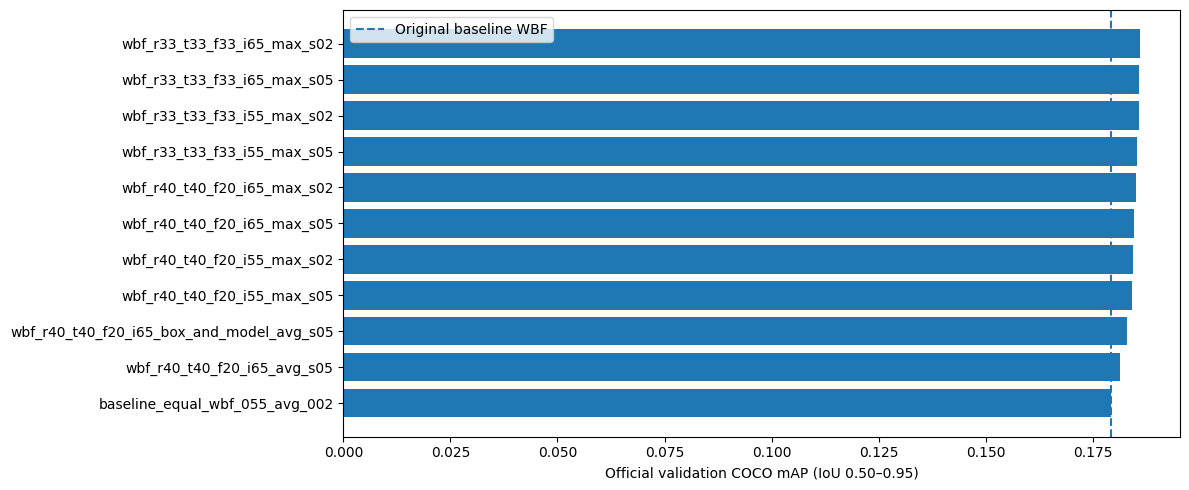

In [10]:
import matplotlib.pyplot as plt
plot=full_df.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,max(5,len(plot)*0.40)))
ax.barh(plot['candidate'],plot['mAP'])
ax.axvline(base_fused_metrics['mAP'],ls='--',label='Original baseline WBF')
ax.set_xlabel('Official validation COCO mAP (IoU 0.50–0.95)')
ax.legend()
fig.tight_layout()
fig.savefig(OUT/'wbf_full_comparison.png',dpi=160)
plt.show()

## 8. Test submission


In [14]:
RUN_TEST = True

In [ ]:
def find_test_metadata():
    opts=list(DATA_ROOT.rglob('test_images.csv'))
    if not opts:opts=list(INPUT.rglob('test_images.csv'))
    if len(opts)!=1:raise FileNotFoundError(f'Ambiguous/missing test_images.csv: {opts}')
    return opts[0]

def make_submission(preds,records,path):
    by_id=grouped(preds); result=[]
    for rec in records:
        iid=str(rec['image_id']); W=float(rec['width']);H=float(rec['height'])
        tokens=[]
        for p in sorted(by_id.get(iid,[]),key=lambda x:x['score'],reverse=True)[:OUTPUT_MAX_DET]:
            cid=int(p['category_id'])-1
            x,y,w,h=map(float,p['bbox'])
            x=max(0.,min(W,x));y=max(0.,min(H,y))
            w=max(0.,min(w,W-x));h=max(0.,min(h,H-y))
            if w<=0 or h<=0:continue
            assert 0<=cid<=7 and 0<=float(p['score'])<=1
            tokens.append(f'{cid} {float(p["score"]):.6f} {x:.2f} {y:.2f} {w:.2f} {h:.2f}')
        result.append({'image_id':iid,'PredictionString':' '.join(tokens)})
    df=pd.DataFrame(result,columns=['image_id','PredictionString'])
    assert df.image_id.is_unique and len(df)==len(records)
    assert all(len(s.split())%6==0 for s in df.PredictionString)
    df.to_csv(path,index=False)
    return df

if RUN_TEST:
    path=find_test_metadata()
    test_df=pd.read_csv(path,dtype={'image_id':str},keep_default_na=False)
    assert {'image_id','file_name','width','height'}.issubset(test_df.columns)
    assert test_df.image_id.is_unique
    test_records=[{'image_id':str(r['image_id']),'file_name':str(r['file_name']),
        'width':int(r['width']),'height':int(r['height'])} for r in test_df.to_dict('records')]
    RAW_TEST={}; TEST_GROUPS={}
    for m in MODELS:
        a=choose_asset('test_'+m,required=True)
        RAW_TEST[m]=normalize_preds(read_asset_json(a),'test')
        TEST_GROUPS[m]=grouped(RAW_TEST[m])
        print('Loaded test:',m,len(RAW_TEST[m]),a.label())
    candidates=FINAL_CHOICES[:TEST_TOP_N]
    if any(item['tiled_fcos'] for item in candidates):
        if not RUN_TILE_TEST or not RUN_TILE_FULL:
            raise RuntimeError('Selected candidate uses tiled FCOS. Enable RUN_TILE_TEST=True (after successful full-val tiled evaluation).')
        RAW_TEST['fcos_tiled']=run_tiled(test_records,'test',OUT/'test_fcos_tiled.json.gz')
    if any(item['tiled_fcos'] for item in candidates) and not RUN_TILE_TEST:
        raise RuntimeError('A selected candidate uses tiled FCOS; set RUN_TILE_TEST=True or disable the tiled candidate.')
    specs_used=[]
    for rank,item in enumerate(candidates,1):
        use_groups=TEST_GROUPS
        if item['tiled_fcos']:
            use_groups=dict(TEST_GROUPS)
            use_groups['fcos']=grouped(RAW_TEST['fcos_tiled'])
        p=wbf_records(test_records,item['spec'],use_groups,progress=True)
        write_gz(OUT/f'test_new_candidate_{rank}.json.gz',p)
        df=make_submission(p,test_records,OUT/f'submission_candidate_{rank}.csv')
        specs_used.append({'rank':rank,'candidate':item['candidate'],
                           'spec':item['spec'],'mAP':item['mAP'],'rows':len(df)})
    shutil.copy2(OUT/'submission_candidate_1.csv',WORK/'submission.csv')
    shutil.copy2(OUT/'submission_candidate_2.csv',WORK/'submission_candidate_2.csv')
    (OUT/'submission_selection.json').write_text(json.dumps(specs_used,indent=2))
    print('Submit:',WORK/'submission.csv','\nSecond option:',WORK/'submission_candidate_2.csv')
else:
    print('RUN_TEST=False. Review full COCO validation before generating submission.')

Loaded test: retina_tta 694697 /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_retina_tta.json
Loaded test: rtdetr 1136046 /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_rtdetr.json
Loaded test: fcos 1143287 /kaggle/input/datasets/nastyadovbenchuk/result-of-assemple/test_fcos.json


wbf_r33_t33_f33_i65_max_s02:   0%|          | 0/3811 [00:00<?, ?it/s]

wbf_r33_t33_f33_i65_max_s05:   0%|          | 0/3811 [00:00<?, ?it/s]

Submit: /kaggle/working/submission.csv 
Second option: /kaggle/working/submission_candidate_2.csv


## 11. Backup, reproducibility та файл із підсумками

In [16]:
config={
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'reference_validation_mAP':GT_REFERENCE_MMAP,
    'reference_public_lb':0.22419,
    'source_predictions':{k:(choose_asset(k).label() if choose_asset(k) else None)
                          for k in ('val_fcos','val_retina_tta','val_rtdetr')},
    'input_sha256':SOURCE_SIGNATURES,'fingerprint':SOURCE_FINGERPRINT,
    'val_frames':len(val_records),'screen_frames':len(screen_records),
    'confidence_min':PRED_SCORE_MIN,'screen_every_n':SCREEN_EVERY_N,
    'weight_grid':WEIGHT_GRID,'iou_grid':IOU_GRID,
    'conf_type_grid':CONF_TYPE_GRID,'skip_thr_grid':SKIP_GRID,
    'winner_wbf':selection,'tiled_full_selection':TILED_FULL_SELECTION,
    'tiled_settings':{'tile_size':TILE_SIZE,'overlap':TILE_OVERLAP,
         'nms_iou':FCOS_TILE_NMS_IOU,'min_size':FCOS_MIN_SIZE,'max_size':FCOS_MAX_SIZE},
}
(OUT/'experiment_config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
manifest=[]
for p in sorted(OUT.rglob('*')):
    if p.is_file() and not p.is_symlink():
        manifest.append({'file':p.relative_to(OUT).as_posix(),'size_bytes':p.stat().st_size})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))

archive=WORK/'ensemble_postprocessing_v2_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
    for p in sorted(OUT.rglob('*')):
        if not p.is_file() or p.is_symlink() or p.suffix in ('.pt','.pth'):continue
        z.write(p,arcname='ensemble_postprocessing_v2/'+p.relative_to(OUT).as_posix())
    if RUN_TEST and (OUT/'submission_selection.json').is_file():
        for name in ('submission.csv','submission_candidate_2.csv'):
            p=WORK/name
            if p.is_file():z.write(p,arcname=name)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    print('Archived files:',len(z.namelist()))
print('Backup:',archive,'Size MB:',round(archive.stat().st_size/1024**2,2))
print('WBF winner:',best_name,'Validation mAP:',selection['mAP'])
print('Submission:',WORK/'submission.csv' if (WORK/'submission.csv').is_file() else 'not generated (RUN_TEST=False)')

Archived files: 16
Backup: /kaggle/working/ensemble_postprocessing_v2_results.zip Size MB: 265.21
WBF winner: wbf_r33_t33_f33_i65_max_s02 Validation mAP: 0.18604802512506466
Submission: /kaggle/working/submission.csv
